# CS × Difusão × Híbridos — trajetória **radial** (baseado na v3 cartesiana)

Mesmo pipeline da v3 cartesiana (divisão por paciente/volume, validação, early stopping, CS ajustado na validação com grade expansível, Híbrido A, Difusão + DC, Difusão + CS regularizado, Wilcoxon por paciente + Holm + IC bootstrap), trocando **apenas o padrão de amostragem** pela trajetória radial.

**Como a trajetória é modelada (leia antes de interpretar os resultados)**
- A trajetória é **rasterizada na grade cartesiana** (cada amostra da trajetória é arredondada ao ponto mais próximo do k-space). Os operadores continuam sendo `máscara × FFT`. **Não há NUFFT, compensação de densidade nem erros de gridding**; é uma aproximação "pseudo-radial" comum na literatura, não uma aquisição não-cartesiana real.
- As máscaras são **conjugado-simétricas** (`M(k) = M(−k)`) por construção. As imagens do dataset são reais, então o k-space é hermitiano; com máscara simétrica o R **não** é subestimado (problema da v3 cartesiana, onde só 50% das linhas tinham espelho amostrado).
- **R efetivo = N² / nº de pontos amostrados**, com `assert` de que bate com `ACCEL_MAX` (±1 ponto). Em níveis de baixa aceleração (R<~1,5), onde o padrão sozinho não alcança a cobertura pedida, o restante é completado com os pontos mais próximos do centro.
- Radial: cada raio é um **diâmetro** do k-space (passa pelo centro), com ângulos uniformes; o nº de raios é o maior que não excede a meta e o restante é completado pelo centro.
- Os valores de PSNR **não são diretamente comparáveis** com os da v3 cartesiana em termos absolutos (padrões diferentes e R efetivo cartesiano ≈ 2× na prática). Compare métodos *dentro* de cada trajetória.

In [1]:
# ============================================================
# 0. Imports e configuração
# ============================================================
import os, re, time, copy, math, warnings
from dataclasses import dataclass

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.fft as fft
from torch.utils.data import Dataset, DataLoader, Subset, TensorDataset

from scipy.io import loadmat
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

try:
    from tqdm.auto import tqdm
except ImportError:
    from tqdm import tqdm

try:
    import pywt
except ImportError:
    !pip install PyWavelets -q
    import pywt

# ---------------- Configuração ----------------
SEED         = 42
IMG_SIZE     = 192
T_MAX        = 20          # níveis de degradação (t = 1..T_MAX, inclusive)

# --- máscara / trajetória ---
ACCEL_MAX    = 3.0         # aceleração EFETIVA em t = T_MAX (ex.: 3, 4, 8, 12)
TRAJECTORY  = "radial"    # "radial" | "spiral"  (padrão de amostragem rasterizado na grade cartesiana)
SPIRAL_FULL_ARMS = 16     # nº de interleaves do espiral para amostragem completa (R=1); usa ~16/R braços

# --- treino da difusão ---
UNET_WIDTH   = 64
EPOCHS       = 120         # máximo de épocas (há early stopping)
PATIENCE     = 12          # épocas sem melhora da loss de validação (t=T)
LR_PATIENCE  = 4           # épocas sem melhora antes de reduzir o LR pela metade
INIT_FROM    = None        # opcional: pesos de outro treino (mesma arquitetura e SEED => mesma divisão) como ponto de partida
MAX_BATCHES  = 400
BATCH        = 4
LR           = 5e-5

# --- divisão dos dados (por paciente/volume) ---
VAL_FRAC     = 0.10
TEST_FRAC    = 0.10
N_VAL_LOSS   = 200         # fatias de validação usadas na loss por época
N_VAL_TUNE   = 24          # fatias de validação usadas para escolher λ
PATIENT_ID_MODE = "file"   # "file" (nome do .mat) | "folder" (pasta) | "prefix" (texto antes do 1º _ ou -)
SLICES_PER_TEST_VOL = 5    # fatias por paciente/volume no teste
CENTRAL_RANGE = (0.2, 0.8) # só fatias centrais do volume (evita fatias quase vazias)

# --- Híbrido A ---
N_CS_CACHE   = 1200        # fatias de treino com CS pré-computado
N_CS_VAL     = 100         # fatias de validação com CS pré-computado
FT_EPOCHS    = 40
FT_PATIENCE  = 6

RUN_TAG      = f"v3_{TRAJECTORY}{ACCEL_MAX:g}x"
WORK_DIR     = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
UNET_PATH    = os.path.join(WORK_DIR, f"unet_{RUN_TAG}.pt")
UNET_FT_PATH = os.path.join(WORK_DIR, f"unet_cs_{RUN_TAG}.pt")
LAST_PATH    = os.path.join(WORK_DIR, f"last_unet_{RUN_TAG}.pt")   # retomada do treino
HIST_PATH    = os.path.join(WORK_DIR, f"hist_unet_{RUN_TAG}.csv")
HIST_FT_PATH = os.path.join(WORK_DIR, f"hist_unet_cs_{RUN_TAG}.csv")
CS_CACHE_TR  = os.path.join(WORK_DIR, f"cs_cache_train_{RUN_TAG}.npz")
CS_CACHE_VA  = os.path.join(WORK_DIR, f"cs_cache_val_{RUN_TAG}.npz")
PRETRAINED   = None   # ATENÇÃO: pesos treinados com todas as fatias / outra máscara invalidam o teste held-out

np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device, "| tag:", RUN_TAG)

def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

Dispositivo: cuda | tag: v3_radial3x


## 1. Dados e divisão por paciente/volume
Cada fatia guarda o **grupo** (paciente/volume) de origem. A divisão é feita **por grupo**, antes de qualquer treino, e os três conjuntos são disjuntos.

> ⚠️ `patient_id_from_path` usa o nome do arquivo `.mat` como identificador (1 arquivo = 1 volume). Se o seu dataset tiver **vários arquivos do mesmo paciente**, ajuste essa função (por exemplo, usando a pasta ou um prefixo do nome) para que todos os volumes de um paciente caiam no mesmo conjunto.

In [2]:
# ============================================================
# 1. Dataset + divisão treino/val/teste POR PACIENTE/VOLUME
# ============================================================
def patient_id_from_path(path):
    # Defina PATIENT_ID_MODE na célula de configuração. Se um paciente tiver VÁRIOS arquivos,
    # use "folder"/"prefix" (ou edite esta função) para que todos caiam no mesmo conjunto.
    stem = os.path.splitext(os.path.basename(path))[0]
    if PATIENT_ID_MODE == "folder":
        return os.path.basename(os.path.dirname(path))
    if PATIENT_ID_MODE == "prefix":
        return re.split(r"[_\-]", stem)[0]
    return stem

class MRIDataset(Dataset):
    def __init__(self, root_dir):
        self.images, self.group, self.pos, self.nsl = [], [], [], []
        print("Carregando dataset...")
        for root, dirs, files in os.walk(root_dir):
            dirs.sort()
            for f in sorted(files):
                if not f.endswith(".mat"):
                    continue
                path = os.path.join(root, f)
                data = loadmat(path)
                if "x" not in data:
                    continue
                x = data["x"]
                gid = patient_id_from_path(path)
                for i in range(x.shape[2]):
                    img = x[:, :, i]
                    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
                    self.images.append(img.astype(np.float32))
                    self.group.append(gid)
                    self.pos.append(i)
                    self.nsl.append(x.shape[2])
        print("Total imagens:", len(self.images), "| grupos (paciente/volume):", len(set(self.group)))

    def __getitem__(self, idx):
        x = torch.tensor(self.images[idx]).float()
        x = (x - x.mean()) / (x.std() + 1e-8)                      # z-score
        x = x.unsqueeze(0).unsqueeze(0)
        x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
        return x.squeeze(0)                                          # (1, H, W)

    def __len__(self):
        return len(self.images)

candidates = [
    "/kaggle/input/datasets/carlosgabrielcranmos/brain-dataset",
    "/kaggle/input/datasets/semnickcharlie/brain-dataset1",
    "/kaggle/input/datasets/semnickcharlie/brain-dataset",
    "/kaggle/input/brain-dataset",
    "/kaggle/input/brain-dataset1",
]
dataset_path = next((p for p in candidates if os.path.isdir(p)), None)
if dataset_path is None:
    for _root in ["/kaggle/input", "."]:
        for r, d, f in os.walk(_root):
            if any(fn.endswith(".mat") for fn in f):
                dataset_path = r
                break
        if dataset_path:
            break
print("dataset_path =", dataset_path)
dataset = MRIDataset(dataset_path)

# ---- diagnóstico dos grupos (confira se 1 grupo = 1 paciente) ----
_gids = sorted(set(dataset.group))
_per = pd.Series(dataset.group).value_counts()
print(f"modo='{PATIENT_ID_MODE}' | exemplos de grupos: {_gids[:6]}")
print(f"fatias por grupo: min={_per.min()} | mediana={int(_per.median())} | max={_per.max()}")
_stems = {re.sub(r"[_\-\s]*\d+$", "", g) for g in _gids}
if len(_stems) < len(_gids):
    print(f"AVISO: {len(_gids)} grupos mas só {len(_stems)} 'prefixos' distintos (ex.: {sorted(_stems)[:4]}). "
          "Pode haver vários volumes do mesmo paciente: considere PATIENT_ID_MODE='prefix' ou 'folder'.")

# ---------- divisão por grupo ----------
def split_groups(groups, val_frac, test_frac, seed):
    ug = sorted(set(groups))
    rng = np.random.RandomState(seed)
    rng.shuffle(ug)
    n = len(ug)
    n_te = max(1, int(round(test_frac * n)))
    n_va = max(1, int(round(val_frac * n)))
    assert n - n_te - n_va >= 1, "Poucos grupos para dividir em treino/val/teste."
    return set(ug[n_te + n_va:]), set(ug[n_te:n_te + n_va]), set(ug[:n_te])

g_train, g_val, g_test = split_groups(dataset.group, VAL_FRAC, TEST_FRAC, SEED)
assert not (g_train & g_val) and not (g_train & g_test) and not (g_val & g_test), "Vazamento: grupos repetidos!"

def indices_of(groups_set):
    return [i for i, g in enumerate(dataset.group) if g in groups_set]

idx_train_all = indices_of(g_train)
idx_val_all   = indices_of(g_val)
idx_test_all  = indices_of(g_test)

def pick_slices(groups_set, k, central=CENTRAL_RANGE):
    # k fatias igualmente espaçadas na região central de cada grupo
    out = []
    for g in sorted(groups_set):
        cand = [i for i in indices_of({g})
                if central[0] <= dataset.pos[i] / dataset.nsl[i] <= central[1]]
        if not cand:
            cand = indices_of({g})
        sel = np.unique(np.linspace(0, len(cand) - 1, min(k, len(cand))).round().astype(int))
        out += [cand[j] for j in sel]
    return out

rng_split = np.random.RandomState(SEED)
idx_val_loss = sorted(rng_split.choice(idx_val_all, size=min(N_VAL_LOSS, len(idx_val_all)), replace=False).tolist())

_tune = pick_slices(g_val, k=max(1, math.ceil(N_VAL_TUNE / max(1, len(g_val)))))
if len(_tune) > N_VAL_TUNE:
    _tune = [_tune[j] for j in np.linspace(0, len(_tune) - 1, N_VAL_TUNE).round().astype(int)]
idx_val_tune = _tune
idx_test = pick_slices(g_test, k=SLICES_PER_TEST_VOL)

print(f"grupos  : treino={len(g_train)} | val={len(g_val)} | teste={len(g_test)}")
print(f"fatias  : treino={len(idx_train_all)} | val(loss)={len(idx_val_loss)} | val(λ)={len(idx_val_tune)} | teste(usadas)={len(idx_test)}")
if len(g_test) < 6:
    print("AVISO: poucos grupos no teste; o teste de Wilcoxon por grupo terá baixo poder (p mínimo = 1/2^n).")

loader = DataLoader(Subset(dataset, idx_train_all), batch_size=BATCH, shuffle=True)

dataset_path = /kaggle/input/datasets/semnickcharlie/brain-dataset1
Carregando dataset...
Total imagens: 4020 | grupos (paciente/volume): 158
modo='file' | exemplos de grupos: ['000301882920_all_slices', '000303269784_all_slices', '000303851049_all_slices', '000304253859_all_slices', '000305738011_all_slices', '000308150214_all_slices']
fatias por grupo: min=21 | mediana=27 | max=27
grupos  : treino=126 | val=16 | teste=16
fatias  : treino=3204 | val(loss)=200 | val(λ)=24 | teste(usadas)=80


## 2. Trajetória radial rasterizada, simétrica, com R efetivo controlado
O nº **total de pontos** amostrados é `round(N² / R)`. O padrão (radial) é gerado, simetrizado em torno do centro do k-space e ajustado para atingir exatamente essa meta (±1 ponto). Para visualizar os padrões e conferir R, veja a figura abaixo.

t=T (radial): 12289 pontos de 36864 | cobertura 0.333 | R efetivo = 3.00x (alvo 3x)
Simetria conjugada da máscara: 100.0% dos pontos (100% = simétrica)


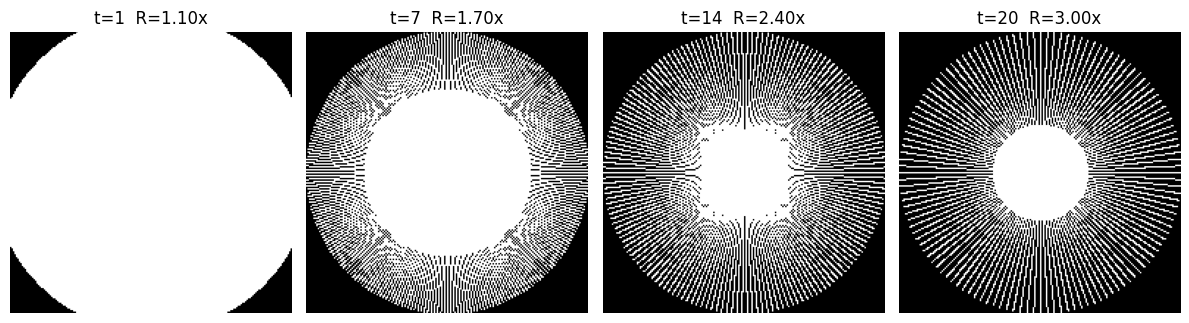

In [3]:
# ============================================================
# 2. Trajetória radial (rasterizada na grade cartesiana), simétrica, R efetivo exato
# ============================================================
_GEO = {}
def _geo(H, W):
    if (H, W) not in _GEO:
        r, c = np.divmod(np.arange(H * W), W)
        partner = ((2 * (H // 2) - r) % H) * W + ((2 * (W // 2) - c) % W)   # espelho (-kx,-ky) em k-space centrado
        rad = np.hypot(r - H // 2, c - W // 2)
        _GEO[(H, W)] = (partner, rad)
    return _GEO[(H, W)]

def _raster(rows, cols, H, W):
    r = np.rint(rows).astype(np.int64).ravel(); c = np.rint(cols).astype(np.int64).ravel()
    ok = (r >= 0) & (r < H) & (c >= 0) & (c < W)
    return np.unique(r[ok] * W + c[ok])

def _sym(flat, H, W):
    partner, _ = _geo(H, W)
    return np.unique(np.concatenate([flat, partner[flat]]))

def _radial_points(n, H, W):
    rmax = min(H, W) / 2
    s = np.linspace(-rmax, rmax, int(4 * rmax) + 1)
    th = np.pi * np.arange(n) / n
    rows = H // 2 + s[None, :] * np.sin(th)[:, None]
    cols = W // 2 + s[None, :] * np.cos(th)[:, None]
    return _sym(_raster(rows, cols, H, W), H, W)

def _spiral_points(n_arms, turns, H, W):
    rmax = min(H, W) / 2
    n_samp = int(max(500, 5 * np.pi * turns * rmax))
    phi = np.linspace(0.0, 2 * np.pi * turns, n_samp)
    rad = rmax * phi / (2 * np.pi * turns)
    psi = 2 * np.pi * np.arange(n_arms) / n_arms
    ang = phi[None, :] + psi[:, None]
    rows = H // 2 + rad[None, :] * np.sin(ang)
    cols = W // 2 + rad[None, :] * np.cos(ang)
    return _sym(_raster(rows, cols, H, W), H, W)

def _adjust(flat, M, H, W):
    partner, rad = _geo(H, W)
    mask = np.zeros(H * W, bool); mask[flat] = True
    n = int(mask.sum())
    if n > M:                                   # remove pares mais distantes do centro
        idx = np.flatnonzero(mask)
        for p in idx[np.argsort(-rad[idx], kind="stable")]:
            if n <= M: break
            if mask[p]:
                mask[p] = False; n -= 1
                q = partner[p]
                if q != p and mask[q]:
                    mask[q] = False; n -= 1
    elif n < M:                                 # completa com pares mais próximos do centro
        idx = np.flatnonzero(~mask)
        for p in idx[np.argsort(rad[idx], kind="stable")]:
            if n >= M: break
            if not mask[p]:
                mask[p] = True; n += 1
                q = partner[p]
                if q != p and not mask[q]:
                    mask[q] = True; n += 1
    return mask

def _fit_radial(M, H, W):
    lo, hi, best = 1, 4 * max(H, W), 1
    while lo <= hi:
        mid = (lo + hi) // 2
        if len(_radial_points(mid, H, W)) <= M: best, lo = mid, mid + 1
        else: hi = mid - 1
    return _radial_points(best, H, W)

def _fit_spiral(M, R, H, W, full_arms=16, max_turns=24.0):
    n_arms = max(1, int(round(full_arms / R)))
    lo, hi = 0.25, max_turns
    if len(_spiral_points(n_arms, hi, H, W)) <= M:
        return _spiral_points(n_arms, hi, H, W)
    for _ in range(16):
        mid = 0.5 * (lo + hi)
        if len(_spiral_points(n_arms, mid, H, W)) <= M: lo = mid
        else: hi = mid
    return _spiral_points(n_arms, lo, H, W)

def make_mask(shape, accel, traj):
    H, W = shape
    M = int(round(H * W / accel))
    flat = _fit_radial(M, H, W) if traj == "radial" else _fit_spiral(M, accel, H, W)
    return _adjust(flat, M, H, W).reshape(H, W), M

def create_mask(shape, accel, traj=None, device="cpu"):
    traj = TRAJECTORY if traj is None else traj
    m, M = make_mask(shape, accel, traj)
    n = int(m.sum())
    assert abs(n - M) <= 2, f"Nº de pontos ({n}) difere da meta ({M})."
    return torch.from_numpy(m.astype(np.float32)).to(device)

_mask_cache = {}
def accel_of(t, T=T_MAX):
    return 1.0 + (ACCEL_MAX - 1.0) * t / T          # t = T  =>  ACCEL_MAX

def get_mask(t, T=T_MAX, shape=(IMG_SIZE, IMG_SIZE)):
    key = (int(t), int(T), shape, str(device))
    if key not in _mask_cache:
        _mask_cache[key] = create_mask(shape, accel_of(t, T), device=device)
    return _mask_cache[key]

def kspace_of(x):                 # k-space centrado, FFT ortonormal
    return fft.fftshift(fft.fft2(x, norm="ortho"), dim=(-2, -1))

def adjoint(k, mask):             # IFFT(mask * k)  (real)
    return fft.ifft2(fft.ifftshift(k * mask, dim=(-2, -1)), norm="ortho").real

def degrade(x, mask):
    k = kspace_of(x) * mask
    return adjoint(k, mask), k

class MRIOperator:
    def __init__(self, mask):
        self.mask = mask
    def forward(self, image):
        return kspace_of(image) * self.mask
    def adjoint(self, k):
        return adjoint(k, self.mask)
    def zero_filled(self, measured):
        return self.adjoint(measured)

# ---- verificação da aceleração efetiva (R = N² / nº de pontos) ----
_m = get_mask(T_MAX, T_MAX)
n_pts = int(_m.sum().item())
R_eff = IMG_SIZE * IMG_SIZE / n_pts
print(f"t=T ({TRAJECTORY}): {n_pts} pontos de {IMG_SIZE * IMG_SIZE} | cobertura {_m.mean().item():.3f} | R efetivo = {R_eff:.2f}x (alvo {ACCEL_MAX:g}x)")
assert abs(R_eff - ACCEL_MAX) / ACCEL_MAX < 0.01, "Aceleração efetiva difere do alvo."
_pt, _ = _geo(IMG_SIZE, IMG_SIZE)
_mf = (_m.cpu().numpy().ravel() > 0)
print(f"Simetria conjugada da máscara: {(_mf == _mf[_pt]).mean():.1%} dos pontos (100% = simétrica)")

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, tt in zip(axes, [1, 7, 14, T_MAX]):
    mm = get_mask(tt, T_MAX)
    ax.imshow(mm.cpu(), cmap="gray")
    ax.set_title(f"t={tt}  R={IMG_SIZE * IMG_SIZE / mm.sum().item():.2f}x"); ax.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, f"mascaras_{RUN_TAG}.png"), dpi=150); plt.show()

## 3. Compressed Sensing: FISTA com Wavelet L1 + TV (inalterado; aceita `x0`)

In [4]:
# ============================================================
# 3. Compressed Sensing: FISTA com Wavelet L1 + TV
# ============================================================
@dataclass
class CSConfig:
    wavelet: str = "db4"
    level: int = 3
    lambda_wavelet_start: float = 0.05
    lambda_wavelet_end: float = 0.0125
    lambda_tv_start: float = 0.001
    lambda_tv_end: float = 0.00025
    use_continuation: bool = True
    schedule: str = "cosine"
    max_iter: int = 150
    tolerance: float = 1e-6
    restart: bool = True
    tv_inner_iter: int = 5

class WaveletOperator:
    def __init__(self, wavelet="db4", level=3):
        self.wavelet, self.level = wavelet, level
        self.coeff_slices, self.coeff_shape = None, None
    def _initialize(self, shape):
        if self.coeff_shape == shape:
            return
        coeffs = pywt.wavedec2(np.zeros(shape), self.wavelet, level=self.level, mode="periodization")
        _, self.coeff_slices = pywt.coeffs_to_array(coeffs)
        self.coeff_shape = shape
    def forward(self, img):
        if torch.is_tensor(img):
            img = img.detach().cpu().numpy()
        self._initialize(img.shape)
        arr, _ = pywt.coeffs_to_array(pywt.wavedec2(img, self.wavelet, level=self.level, mode="periodization"))
        return arr
    def inverse(self, arr):
        coeffs = pywt.array_to_coeffs(arr, self.coeff_slices, output_format="wavedec2")
        img = pywt.waverec2(coeffs, self.wavelet, mode="periodization")
        H, W = self.coeff_shape
        return torch.tensor(img[:H, :W], dtype=torch.float32)

def soft_threshold(c, lam):
    return np.sign(c) * np.maximum(np.abs(c) - lam, 0.0)

def tv_denoise_chambolle(image, weight=0.01, max_iter=5, eps=1e-4):
    px = torch.zeros_like(image); py = torch.zeros_like(image)
    tau = 0.25
    u = image.clone()
    for _ in range(max_iter):
        u_old = u.clone()
        gradx = torch.zeros_like(u); grady = torch.zeros_like(u)
        gradx[:-1, :] = u[1:, :] - u[:-1, :]
        grady[:, :-1] = u[:, 1:] - u[:, :-1]
        px = px + tau * gradx; py = py + tau * grady
        norm = torch.maximum(torch.ones_like(px), torch.sqrt(px ** 2 + py ** 2))
        px /= norm; py /= norm
        div = torch.zeros_like(u)
        div[1:, :] += px[:-1, :]; div[:-1, :] -= px[:-1, :]
        div[:, 1:] += py[:, :-1]; div[:, :-1] -= py[:, :-1]
        u = image + weight * div
        if torch.norm(u - u_old) < eps:
            break
    return u

class LambdaScheduler:
    def __init__(self, lam_start, lam_end, max_iter, schedule="cosine"):
        self.a, self.b, self.n, self.s = lam_start, lam_end, max_iter, schedule
    def __call__(self, it):
        t = it / max(self.n - 1, 1)
        alpha = {"linear": t, "quadratic": t ** 2}.get(self.s, 0.5 * (1 - np.cos(np.pi * t)))
        return self.a * (1 - alpha) + self.b * alpha

class FISTA:
    def __init__(self, config):
        self.config = config
        self.wavelet = WaveletOperator(config.wavelet, config.level)

    def solve(self, measured, mask, x0=None):
        cfg = self.config
        op = MRIOperator(mask)
        x = op.zero_filled(measured) if x0 is None else x0.detach().clone()
        y = x.clone()
        t = 1.0
        if cfg.use_continuation:
            wv = LambdaScheduler(cfg.lambda_wavelet_start, cfg.lambda_wavelet_end, cfg.max_iter, cfg.schedule)
            tvs = LambdaScheduler(cfg.lambda_tv_start, cfg.lambda_tv_end, cfg.max_iter, cfg.schedule)
        else:
            wv = lambda it: cfg.lambda_wavelet_start
            tvs = lambda it: cfg.lambda_tv_start

        for it in range(cfg.max_iter):
            x_prev = x.clone()
            x = y - op.adjoint(op.forward(y) - measured)                # passo de gradiente (L = 1)
            coeff = soft_threshold(self.wavelet.forward(x), wv(it))     # prox Wavelet L1
            x = self.wavelet.inverse(coeff).to(measured.device)
            ltv = tvs(it)
            if ltv > 0:                                                  # prox TV
                x = tv_denoise_chambolle(x, weight=ltv, max_iter=cfg.tv_inner_iter)
            t_new = (1 + np.sqrt(1 + 4 * t * t)) / 2                     # FISTA
            y = x + ((t - 1) / t_new) * (x - x_prev)
            if cfg.restart and torch.sum((x - y) * (x - x_prev)) > 0:
                t = 1.0; y = x.clone()
            else:
                t = t_new
            if torch.norm(x - x_prev) / (torch.norm(x_prev) + 1e-8) < cfg.tolerance:
                break
        return x

def make_cfg(lw, ltv, iters=150):
    return CSConfig(lambda_wavelet_start=lw, lambda_wavelet_end=lw * 0.25,
                    lambda_tv_start=ltv, lambda_tv_end=ltv * 0.25, max_iter=iters)

## 4. U-Net, treino com validação e reconstrução
Mudanças: `t ∈ [1, T_MAX]` **inclusivo** (o nível usado na inferência agora é treinado), loss de validação por época (em `t=T_MAX`, condição de teste, e em `t` aleatório com semente fixa), *early stopping* e restauração do melhor checkpoint.

In [5]:
# ============================================================
# 4. U-Net + treino com validação + reconstrução
# ============================================================
class UNet(nn.Module):
    def __init__(self, w=64):
        super().__init__()
        self.w = w
        self.time_mlp = nn.Sequential(nn.Linear(1, 256), nn.ReLU(), nn.Linear(256, 8 * w))
        self.conv1 = nn.Conv2d(1, w, 3, padding=1)
        self.conv2 = nn.Conv2d(w, 2 * w, 3, padding=1)
        self.conv3 = nn.Conv2d(2 * w, 4 * w, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = nn.Conv2d(4 * w, 8 * w, 3, padding=1)
        self.up1 = nn.ConvTranspose2d(8 * w, 4 * w, 2, 2)
        self.up2 = nn.ConvTranspose2d(4 * w, 2 * w, 2, 2)
        self.conv4 = nn.Conv2d(8 * w, 4 * w, 3, padding=1)
        self.conv5 = nn.Conv2d(3 * w, 2 * w, 3, padding=1)
        self.out = nn.Conv2d(2 * w, 1, 1)

    def forward(self, x, t):
        t = t.view(-1, 1)
        t_emb = self.time_mlp(t).view(-1, 8 * self.w, 1, 1)
        e1 = F.relu(self.conv1(x))
        e2 = F.relu(self.conv2(self.pool(e1)))
        e3 = F.relu(self.conv3(self.pool(e2)))
        b = F.relu(self.bottleneck(e3) + t_emb)
        d1 = self.up1(b)
        if d1.shape[-2:] != e3.shape[-2:]:
            d1 = F.interpolate(d1, size=e3.shape[-2:], mode="bilinear", align_corners=False)
        d1 = F.relu(self.conv4(torch.cat([d1, e3], dim=1)))
        d2 = self.up2(d1)
        if d2.shape[-2:] != e1.shape[-2:]:
            d2 = F.interpolate(d2, size=e1.shape[-2:], mode="bilinear", align_corners=False)
        d2 = F.relu(self.conv5(torch.cat([d2, e1], dim=1)))
        return self.out(d2)                        # resíduo: x_hat = x_in - saída


def _loss_batch(model, x, t):
    masks = torch.stack([get_mask(int(tt), T_MAX) for tt in t]).unsqueeze(1)
    x_t, _ = degrade(x, masks)
    pred = model(x_t, (t.float() / T_MAX).to(device))
    return torch.abs((x_t - pred) - x).mean()


@torch.no_grad()
def val_loss(model, idxs, batch=16):
    # devolve (loss em t=T_MAX, loss em t aleatório com semente fixa)
    model.eval()
    g = torch.Generator().manual_seed(SEED)
    tot_T, tot_R, n = 0.0, 0.0, 0
    for s in range(0, len(idxs), batch):
        x = torch.stack([dataset[i] for i in idxs[s:s + batch]]).to(device)
        tT = torch.full((len(x),), T_MAX)
        tR = torch.randint(1, T_MAX + 1, (len(x),), generator=g)
        tot_T += _loss_batch(model, x, tT).item() * len(x)
        tot_R += _loss_batch(model, x, tR).item() * len(x)
        n += len(x)
    return tot_T / n, tot_R / n


def train_unet(model, loader, epochs, val_idxs, T_max=T_MAX, max_batches=MAX_BATCHES, lr=LR,
               patience=PATIENCE, save_path=None, last_path=None):
    opt = torch.optim.Adam(model.parameters(), lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=LR_PATIENCE, min_lr=1e-6)
    best, best_state, bad, hist, start = float("inf"), None, 0, [], 0

    if last_path and os.path.exists(last_path):                      # retomada (ex.: sessão do Kaggle caiu)
        ck = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        best, bad, hist, start, best_state = ck["best"], ck["bad"], ck["hist"], ck["epoch"] + 1, ck["best_state"]
        print(f"Retomando da época {start} (melhor val(t=T) até aqui = {best:.5f})")
        if bad >= patience:                                          # já havia parado por early stopping
            start = epochs

    for epoch in range(start, epochs):
        model.train()
        total, count = 0.0, 0
        for i, x in enumerate(loader):
            if i >= max_batches:
                break
            x = x.to(device)
            t = torch.randint(1, T_max + 1, (x.shape[0],))          # 1..T_max INCLUSIVE
            loss = _loss_batch(model, x, t)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item(); count += 1
        vT, vR = val_loss(model, val_idxs)
        sched.step(vT)
        hist.append({"epoch": epoch, "train": total / max(count, 1), "val_T": vT, "val_rand": vR,
                     "lr": opt.param_groups[0]["lr"]})
        flag = ""
        if vT < best - 1e-6:
            best, bad, flag = vT, 0, "  *"
            best_state = copy.deepcopy(model.state_dict())
            if save_path:
                torch.save(best_state, save_path)
        else:
            bad += 1
        print(f"Epoch {epoch:3d} | train {hist[-1]['train']:.5f} | val(t=T) {vT:.5f} | val(t~U) {vR:.5f} | lr {hist[-1]['lr']:.1e}{flag}")
        if last_path:
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                        "best": best, "bad": bad, "hist": hist, "epoch": epoch, "best_state": best_state}, last_path)
        if bad >= patience:
            print(f"Early stopping na época {epoch} (melhor val(t=T) = {best:.5f})")
            break
    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(hist)


@torch.no_grad()
def recon_unet(model, y, mask, x_in=None):
    # Passo da U-Net em t=T (entrada normalizada = 1) + consistência de dados no k-space.
    # x_in: imagem de entrada (padrão: zero-filled). No Híbrido A é a saída do CS.
    if x_in is None:
        x_in = adjoint(y, mask)
    inp = x_in[None, None]
    res = model(inp, torch.ones(1, device=inp.device))
    x_hat = (inp - res)[0, 0]
    k_new = mask * y + (1 - mask) * kspace_of(x_hat)
    return fft.ifft2(fft.ifftshift(k_new, dim=(-2, -1)), norm="ortho").real

Epoch   0 | train 0.05590 | val(t=T) 0.07319 | val(t~U) 0.04880 | lr 5.0e-05  *
Epoch   1 | train 0.04768 | val(t=T) 0.06867 | val(t~U) 0.04540 | lr 5.0e-05  *
Epoch   2 | train 0.04634 | val(t=T) 0.06678 | val(t~U) 0.04420 | lr 5.0e-05  *
Epoch   3 | train 0.04438 | val(t=T) 0.06572 | val(t~U) 0.04380 | lr 5.0e-05  *
Epoch   4 | train 0.04415 | val(t=T) 0.06481 | val(t~U) 0.04309 | lr 5.0e-05  *
Epoch   5 | train 0.04263 | val(t=T) 0.06396 | val(t~U) 0.04258 | lr 5.0e-05  *
Epoch   6 | train 0.04292 | val(t=T) 0.06334 | val(t~U) 0.04233 | lr 5.0e-05  *
Epoch   7 | train 0.04305 | val(t=T) 0.06285 | val(t~U) 0.04198 | lr 5.0e-05  *
Epoch   8 | train 0.04218 | val(t=T) 0.06469 | val(t~U) 0.04329 | lr 5.0e-05
Epoch   9 | train 0.04332 | val(t=T) 0.06191 | val(t~U) 0.04185 | lr 5.0e-05  *
Epoch  10 | train 0.04190 | val(t=T) 0.06078 | val(t~U) 0.04096 | lr 5.0e-05  *
Epoch  11 | train 0.04069 | val(t=T) 0.06063 | val(t~U) 0.04093 | lr 5.0e-05  *
Epoch  12 | train 0.04199 | val(t=T) 0.0602

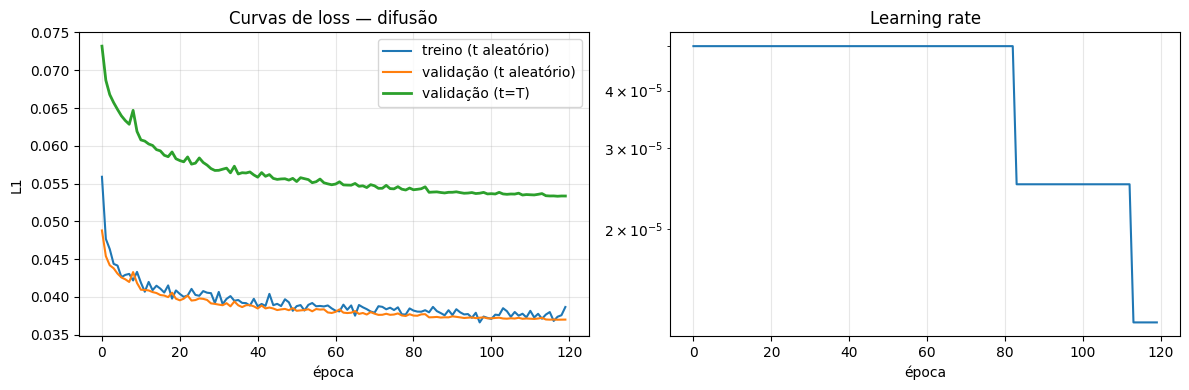

Melhor checkpoint: época 117 de 120 treinadas (val(t=T) = 0.05333)
Comparação justa (mesma distribuição de t): treino = 0.03867 | val(t~U) = 0.03701 | diferença = -0.00166
Diferença ≈ 0 => sem overfitting; val(t=T) é maior só porque t=T é o nível mais difícil (não deve ser comparado com a loss de treino, que é a média sobre todos os t).
AVISO: o melhor checkpoint está nas últimas épocas — o modelo ainda melhorava; aumente EPOCHS ou continue via INIT_FROM.


In [6]:
# ============================================================
# 5. Treino da difusão (ou carregamento)
# ============================================================
model = UNet(UNET_WIDTH).to(device)
hist = None

if PRETRAINED and os.path.exists(PRETRAINED):
    model.load_state_dict(torch.load(PRETRAINED, map_location=device))
    print("Pesos carregados de", PRETRAINED)
    print("AVISO: se essa U-Net viu fatias de val/teste ou outra máscara, o teste NÃO é held-out.")
elif os.path.exists(UNET_PATH) and not os.path.exists(LAST_PATH):
    model.load_state_dict(torch.load(UNET_PATH, map_location=device))
    print("Pesos carregados de", UNET_PATH)
    if os.path.exists(HIST_PATH):
        hist = pd.read_csv(HIST_PATH)
else:
    if INIT_FROM and os.path.exists(INIT_FROM) and not os.path.exists(LAST_PATH):
        model.load_state_dict(torch.load(INIT_FROM, map_location=device))
        print("Inicializando a partir de", INIT_FROM, "(o treino continua com as mesmas divisões treino/val/teste)")
    t0 = time.time()
    model, hist = train_unet(model, loader, EPOCHS, idx_val_loss, save_path=UNET_PATH, last_path=LAST_PATH)
    hist.to_csv(HIST_PATH, index=False)
    print(f"Treino concluído em {(time.time() - t0) / 60:.1f} min | melhor checkpoint em {UNET_PATH}")
model.eval()

if hist is not None:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist.epoch, hist.train, label="treino (t aleatório)")
    ax[0].plot(hist.epoch, hist.val_rand, label="validação (t aleatório)")
    ax[0].plot(hist.epoch, hist.val_T, label="validação (t=T)", lw=2)
    ax[0].set_xlabel("época"); ax[0].set_ylabel("L1"); ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[0].set_title("Curvas de loss — difusão")
    if "lr" in hist:
        ax[1].semilogy(hist.epoch, hist.lr); ax[1].set_title("Learning rate"); ax[1].set_xlabel("época"); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, f"loss_{RUN_TAG}.png"), dpi=150); plt.show()

    last, best_ep = hist.iloc[-1], int(hist.val_T.idxmin())
    print(f"Melhor checkpoint: época {int(hist.epoch.iloc[best_ep])} de {len(hist)} treinadas (val(t=T) = {hist.val_T.min():.5f})")
    print(f"Comparação justa (mesma distribuição de t): treino = {last.train:.5f} | val(t~U) = {last.val_rand:.5f} "
          f"| diferença = {last.val_rand - last.train:+.5f}")
    print("Diferença ≈ 0 => sem overfitting; val(t=T) é maior só porque t=T é o nível mais difícil "
          "(não deve ser comparado com a loss de treino, que é a média sobre todos os t).")
    if best_ep >= len(hist) - 3:
        print("AVISO: o melhor checkpoint está nas últimas épocas — o modelo ainda melhorava; aumente EPOCHS ou continue via INIT_FROM.")

## 6. Ajuste do CS na **validação** (grade ampliada, com expansão automática)
Na v2 o melhor λ caiu na borda da grade. Agora:
- a grade inclui **λw = 0** (sem wavelet) e **λtv = 0** (sem TV): se o melhor for 0, o prior correspondente não está ajudando;
- enquanto o melhor ponto estiver na borda (e a borda não for 0), a grade se **expande** (até `MAX_EXPAND` rodadas);
- depois, o **número de iterações** do FISTA é escolhido (100 / 300 / 600; o menor que ficar a ≤0,05 dB do melhor);
- o PSNR do **zero-filled** na validação é mostrado como referência: um CS que não o supera claramente está mal ajustado.

In [7]:
# ============================================================
# 6. Grid search de λ do CS (validação) com expansão automática
# ============================================================
def val_psnr(cfg, idxs=None, init_from_unet=False):
    idxs = idx_val_tune if idxs is None else idxs
    ps = []
    for i in idxs:
        gt = dataset[i][0].to(device)
        mask = get_mask(T_MAX, T_MAX)
        y = kspace_of(gt) * mask
        x0 = recon_unet(model, y, mask) if init_from_unet else None
        x = FISTA(cfg).solve(y, mask, x0=x0)
        g, p = gt.cpu().numpy(), x.cpu().numpy()
        ps.append(peak_signal_noise_ratio(g, p, data_range=g.max() - g.min()))
    return float(np.mean(ps))

# referência: zero-filled na validação
_zf = []
for i in idx_val_tune:
    g = dataset[i][0].to(device); m = get_mask(T_MAX, T_MAX)
    _zf.append(peak_signal_noise_ratio(g.cpu().numpy(), adjoint(kspace_of(g) * m, m).cpu().numpy(),
                                       data_range=float(g.max() - g.min())))
P_ZF_VAL = float(np.mean(_zf))
print(f"Referência (validação): zero-filled = {P_ZF_VAL:.2f} dB\n")

CS_TUNE_ITERS = 100
LWs  = [0.0, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1]
LTVs = [0.0, 0.00005, 0.0002, 0.001, 0.004]
MAX_EXPAND = 3
_res = {}

def eval_cs(lw, ltv, iters=CS_TUNE_ITERS):
    k = (lw, ltv, iters)
    if k not in _res:
        _res[k] = val_psnr(make_cfg(lw, ltv, iters=iters))
        print(f"λw={lw:<9.5g} λtv={ltv:<9.5g} it={iters:<4d} -> {_res[k]:.2f} dB")
    return _res[k]

for rnd in range(MAX_EXPAND + 1):
    for lw in LWs:
        for ltv in LTVs:
            eval_cs(lw, ltv)
    (lw_b, ltv_b, _), p_b = max(((k, v) for k, v in _res.items() if k[2] == CS_TUNE_ITERS), key=lambda kv: kv[1])
    grew = False
    pos = [v for v in LWs if v > 0]
    if lw_b > 0 and lw_b == min(pos) and lw_b > 1e-5:
        LWs.append(float(f"{lw_b / 3.16:.2g}")); grew = True
    if lw_b == max(LWs) and lw_b > 0:
        LWs.append(float(f"{lw_b * 3.16:.2g}")); grew = True
    if ltv_b == max(LTVs):
        LTVs.append(float(f"{ltv_b * 4:.2g}")); grew = True
    LWs, LTVs = sorted(set(LWs)), sorted(set(LTVs))
    if not grew:
        break
    print(f"-- melhor ponto na borda; expandindo a grade (rodada {rnd + 1}/{MAX_EXPAND}) --")

LW_BEST, LTV_BEST = float(lw_b), float(ltv_b)
df_grid = pd.DataFrame([{"lw": k[0], "ltv": k[1], "psnr_val": v} for k, v in _res.items() if k[2] == CS_TUNE_ITERS])
print("\nPSNR de validação (linhas = λw, colunas = λtv):")
print(df_grid.pivot(index="lw", columns="ltv", values="psnr_val").round(2).to_string())
print(f"\nMelhor: λw={LW_BEST:g} | λtv={LTV_BEST:g} | PSNR val = {p_b:.2f} dB (zero-filled: {P_ZF_VAL:.2f} dB, ganho {p_b - P_ZF_VAL:+.2f} dB)")
if LW_BEST == 0:
    print("NOTA: o melhor λw é 0 -> o prior Wavelet L1 não está ajudando nesta configuração.")
if LTV_BEST == 0:
    print("NOTA: o melhor λtv é 0 -> o prior TV não está ajudando nesta configuração.")
if p_b - P_ZF_VAL < 0.5:
    print("AVISO: o CS ganha <0,5 dB sobre o zero-filled; a comparação 'difusão vs CS' deve ser lida com cautela "
          "(considere outro dicionário/regularizador ou mais iterações).")

# ---- nº de iterações ----
ITER_GRID = [100, 300, 600]
it_res = {n: eval_cs(LW_BEST, LTV_BEST, n) for n in ITER_GRID}
top = max(it_res.values())
CS_ITERS = min(n for n, v in it_res.items() if v >= top - 0.05)
CFG_CS = make_cfg(LW_BEST, LTV_BEST, iters=CS_ITERS)
print(f"\nIterações do FISTA: {it_res} -> usando {CS_ITERS}")
df_grid.to_csv(os.path.join(WORK_DIR, f"grid_cs_{RUN_TAG}.csv"), index=False)
pd.Series(it_res, name="psnr_val").to_csv(os.path.join(WORK_DIR, f"iters_cs_{RUN_TAG}.csv"))

Referência (validação): zero-filled = 32.22 dB

λw=0         λtv=0         it=100  -> 32.22 dB
λw=0         λtv=5e-05     it=100  -> 32.16 dB
λw=0         λtv=0.0002    it=100  -> 31.95 dB
λw=0         λtv=0.001     it=100  -> 28.57 dB
λw=0         λtv=0.004     it=100  -> 6.11 dB
λw=0.0003    λtv=0         it=100  -> 33.61 dB
λw=0.0003    λtv=5e-05     it=100  -> 33.56 dB
λw=0.0003    λtv=0.0002    it=100  -> 33.39 dB
λw=0.0003    λtv=0.001     it=100  -> 28.88 dB
λw=0.0003    λtv=0.004     it=100  -> 2.77 dB
λw=0.001     λtv=0         it=100  -> 34.34 dB
λw=0.001     λtv=5e-05     it=100  -> 34.30 dB
λw=0.001     λtv=0.0002    it=100  -> 34.13 dB
λw=0.001     λtv=0.001     it=100  -> 31.05 dB
λw=0.001     λtv=0.004     it=100  -> 3.79 dB
λw=0.003     λtv=0         it=100  -> 34.41 dB
λw=0.003     λtv=5e-05     it=100  -> 34.37 dB
λw=0.003     λtv=0.0002    it=100  -> 34.26 dB
λw=0.003     λtv=0.001     it=100  -> 33.18 dB
λw=0.003     λtv=0.004     it=100  -> 7.72 dB
λw=0.01      λtv

## 7. Refinamento da saída da difusão: dois métodos distintos
- **Difusão + DC (FISTA, λ = 0):** só projeta/ajusta a saída da difusão para ficar consistente com os dados adquiridos (nenhum prior de CS).
- **Difusão + CS regularizado (λ > 0):** FISTA com Wavelet+TV em fração do λ ótimo do CS puro. O fator é escolhido na validação **entre os valores > 0**.

Assim a pergunta "o prior de CS acrescenta algo depois da difusão?" é respondida comparando os dois.

In [8]:
# ============================================================
# 7. Difusão + DC (λ=0)  vs  Difusão + CS regularizado (λ>0)
# ============================================================
ITERS_B = 50
FACS = [0.0, 0.03, 0.1, 0.3, 1.0]
BASE_LW  = LW_BEST  if LW_BEST  > 0 else 0.01      # se o CS escolheu 0, usa um λ de referência para o B2
BASE_LTV = LTV_BEST if LTV_BEST > 0 else 0.0002
if LW_BEST == 0 or LTV_BEST == 0:
    print(f"NOTA: usando λ de referência (λw={BASE_LW:g}, λtv={BASE_LTV:g}) como base dos fatores do B2.")
rows = []
for fac in FACS:
    cfg_b = make_cfg(BASE_LW * fac, BASE_LTV * fac, iters=ITERS_B)
    p = val_psnr(cfg_b, init_from_unet=True)
    rows.append({"fator": fac, "psnr_val": p})
    print(f"fator λ = {fac:<5} -> {p:.2f} dB")
df_b = pd.DataFrame(rows)

CFG_B1 = make_cfg(0.0, 0.0, iters=ITERS_B)                                   # Difusão + DC
FAC_B2 = float(df_b[df_b.fator > 0].sort_values("psnr_val").iloc[-1].fator)   # melhor λ>0
CFG_B2 = make_cfg(BASE_LW * FAC_B2, BASE_LTV * FAC_B2, iters=ITERS_B)
print(f"\nB1 (Difusão + DC): λ=0 | B2 (Difusão + CS reg.): fator={FAC_B2}")

def _psnr(g, p):
    return peak_signal_noise_ratio(g, p, data_range=g.max() - g.min())
p_unet_val = np.mean([
    _psnr(dataset[i][0].numpy(),
          recon_unet(model, kspace_of(dataset[i][0].to(device)) * get_mask(T_MAX, T_MAX), get_mask(T_MAX, T_MAX)).cpu().numpy())
    for i in idx_val_tune])
print(f"(referência: difusão pura na validação = {p_unet_val:.2f} dB)")
df_b.to_csv(os.path.join(WORK_DIR, f"grid_B_{RUN_TAG}.csv"), index=False)

NOTA: usando λ de referência (λw=0.1, λtv=0.0002) como base dos fatores do B2.
fator λ = 0.0   -> 37.61 dB
fator λ = 0.03  -> 35.95 dB
fator λ = 0.1   -> 34.78 dB
fator λ = 0.3   -> 34.36 dB
fator λ = 1.0   -> 34.47 dB

B1 (Difusão + DC): λ=0 | B2 (Difusão + CS reg.): fator=0.03
(referência: difusão pura na validação = 37.61 dB)


## 8. Híbrido A: CS → U-Net
A U-Net é ajustada (*fine-tune*) com entradas = saídas do CS (já com λ/iterações ajustados na seção 6) em `t=T`. Mudanças da v3: mais fatias (1200), até 40 épocas com **early stopping** pela loss de validação e restauração do melhor checkpoint. Os *caches* do CS guardam uma assinatura e são recalculados se algo mudar (o CS mais bem ajustado invalida o cache da v2 por construção).

In [9]:
# ============================================================
# 8. Pré-computa o CS e ajusta a U-Net (Híbrido A)
# ============================================================
def cache_signature(idxs, cfg):
    return f"{list(idxs)}|{cfg}|R={ACCEL_MAX}|traj={TRAJECTORY}|N={IMG_SIZE}"

def build_cs_cache(idxs, cfg, path, desc):
    sig = cache_signature(idxs, cfg)
    if os.path.exists(path):
        z = np.load(path, allow_pickle=False)
        if str(z["sig"]) == sig:
            print("Cache do CS carregado:", path)
            return z["cs"]
        print("Cache desatualizado; recalculando:", path)
    out = []
    for i in tqdm(idxs, desc=desc):
        gt = dataset[i][0].to(device)
        mask = get_mask(T_MAX, T_MAX)
        out.append(FISTA(cfg).solve(kspace_of(gt) * mask, mask).cpu().numpy())
    out = np.stack(out).astype(np.float32)
    np.savez(path, sig=np.array(sig), cs=out)
    return out

rng = np.random.RandomState(SEED)
idx_ft     = sorted(rng.choice(idx_train_all, size=min(N_CS_CACHE, len(idx_train_all)), replace=False).tolist())
idx_ft_val = sorted(rng.choice(idx_val_all,   size=min(N_CS_VAL,   len(idx_val_all)),   replace=False).tolist())

cs_train = build_cs_cache(idx_ft,     CFG_CS, CS_CACHE_TR, "CS (treino)")
cs_val   = build_cs_cache(idx_ft_val, CFG_CS, CS_CACHE_VA, "CS (val)")

gt_train, gt_val = torch.stack([dataset[i] for i in idx_ft]), torch.stack([dataset[i] for i in idx_ft_val])
ft_loader = DataLoader(TensorDataset(torch.from_numpy(cs_train).unsqueeze(1), gt_train), batch_size=BATCH, shuffle=True)
cs_val_t = torch.from_numpy(cs_val).unsqueeze(1)

@torch.no_grad()
def ft_val_loss(m):
    m.eval(); tot, n = 0.0, 0
    for s in range(0, len(cs_val_t), 16):
        xcs, xgt = cs_val_t[s:s + 16].to(device), gt_val[s:s + 16].to(device)
        pred = m(xcs, torch.ones(xcs.shape[0], device=device))
        tot += torch.abs((xcs - pred) - xgt).mean().item() * len(xcs); n += len(xcs)
    return tot / n

model_A = copy.deepcopy(model)
if os.path.exists(UNET_FT_PATH):
    model_A.load_state_dict(torch.load(UNET_FT_PATH, map_location=device))
    print("Pesos do Híbrido A carregados de", UNET_FT_PATH)
else:
    opt = torch.optim.Adam(model_A.parameters(), LR)
    best_v, best_state, bad, hist_ft = ft_val_loss(model_A), copy.deepcopy(model_A.state_dict()), 0, []
    print(f"FT epoch  -1 | val {best_v:.5f}  (ponto de partida = U-Net da difusão)")
    for ep in range(FT_EPOCHS):
        model_A.train(); tot, cnt = 0.0, 0
        for xcs, xgt in ft_loader:
            xcs, xgt = xcs.to(device), xgt.to(device)
            pred = model_A(xcs, torch.ones(xcs.shape[0], device=device))
            loss = torch.abs((xcs - pred) - xgt).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item(); cnt += 1
        v = ft_val_loss(model_A)
        hist_ft.append({"epoch": ep, "train": tot / cnt, "val": v})
        flag = ""
        if v < best_v - 1e-6:
            best_v, best_state, bad, flag = v, copy.deepcopy(model_A.state_dict()), 0, "  *"
        else:
            bad += 1
        print(f"FT epoch {ep:3d} | train {tot / cnt:.5f} | val {v:.5f}{flag}")
        if bad >= FT_PATIENCE:
            print(f"Early stopping do ajuste fino na época {ep}")
            break
    model_A.load_state_dict(best_state)
    torch.save(best_state, UNET_FT_PATH)
    pd.DataFrame(hist_ft).to_csv(HIST_FT_PATH, index=False)
model_A.eval();

CS (treino):   0%|          | 0/1200 [00:00<?, ?it/s]

CS (val):   0%|          | 0/100 [00:00<?, ?it/s]

FT epoch  -1 | val 0.07746  (ponto de partida = U-Net da difusão)
FT epoch   0 | train 0.05558 | val 0.05283  *
FT epoch   1 | train 0.05428 | val 0.05249  *
FT epoch   2 | train 0.05395 | val 0.05234  *
FT epoch   3 | train 0.05375 | val 0.05209  *
FT epoch   4 | train 0.05353 | val 0.05219
FT epoch   5 | train 0.05349 | val 0.05197  *
FT epoch   6 | train 0.05332 | val 0.05194  *
FT epoch   7 | train 0.05328 | val 0.05182  *
FT epoch   8 | train 0.05307 | val 0.05191
FT epoch   9 | train 0.05307 | val 0.05183
FT epoch  10 | train 0.05293 | val 0.05173  *
FT epoch  11 | train 0.05285 | val 0.05188
FT epoch  12 | train 0.05282 | val 0.05181
FT epoch  13 | train 0.05274 | val 0.05168  *
FT epoch  14 | train 0.05264 | val 0.05176
FT epoch  15 | train 0.05259 | val 0.05159  *
FT epoch  16 | train 0.05248 | val 0.05156  *
FT epoch  17 | train 0.05243 | val 0.05153  *
FT epoch  18 | train 0.05235 | val 0.05165
FT epoch  19 | train 0.05237 | val 0.05151  *
FT epoch  20 | train 0.05219 | val 

## 9. Avaliação no conjunto de **teste**
Fatias de pacientes/volumes que **não** aparecem no treino nem na validação. Cada fatia é rotulada com seu grupo, e o tempo de reconstrução de cada método é medido (pipeline completo: no Híbrido A inclui o CS; nos B1/B2 inclui a difusão).

In [10]:
# ============================================================
# 9. Avaliação: 6 métodos nas mesmas fatias de teste
# ============================================================
M_ZF, M_CS, M_DIF = "Zero-filled", "CS (Wavelet+TV)", "Difusão"
M_A, M_B1, M_B2   = "Híbrido A (CS→U-Net)", "Difusão + DC (λ=0)", "Difusão + CS reg. (λ>0)"
METHODS = [M_ZF, M_CS, M_DIF, M_A, M_B1, M_B2]

def metrics(gt, pred, y, mask):
    g, p = gt.cpu().numpy(), pred.detach().cpu().numpy()
    dr = g.max() - g.min()
    psnr = peak_signal_noise_ratio(g, p, data_range=dr)
    ssim = structural_similarity(g, p, data_range=dr)
    nmse = float(np.sum((g - p) ** 2) / (np.sum(g ** 2) + 1e-12))
    dc = float(torch.linalg.norm(mask * kspace_of(pred) - y) / (torch.linalg.norm(y) + 1e-12))
    return psnr, ssim, nmse, dc

def timed(fn):
    sync(); t0 = time.time(); out = fn(); sync()
    return out, time.time() - t0

rows, store = [], {}
for i in tqdm(idx_test, desc="Teste"):
    gt = dataset[i][0].to(device)
    mask = get_mask(T_MAX, T_MAX)
    y = kspace_of(gt) * mask

    zf, t_zf   = timed(lambda: adjoint(y, mask))
    cs, t_cs   = timed(lambda: FISTA(CFG_CS).solve(y, mask))
    dif, t_dif = timed(lambda: recon_unet(model, y, mask))
    hA, t_hA   = timed(lambda: recon_unet(model_A, y, mask, x_in=cs))
    hB1, t_b1  = timed(lambda: FISTA(CFG_B1).solve(y, mask, x0=dif))
    hB2, t_b2  = timed(lambda: FISTA(CFG_B2).solve(y, mask, x0=dif))

    recs  = [zf, cs, dif, hA, hB1, hB2]
    times = [t_zf, t_cs, t_dif, t_cs + t_hA, t_dif + t_b1, t_dif + t_b2]
    for name, r, tt in zip(METHODS, recs, times):
        p, s, nm, dc = metrics(gt, r, y, mask)
        rows.append({"idx": i, "grupo": dataset.group[i], "Método": name,
                     "PSNR": p, "SSIM": s, "NMSE": nm, "Erro DC": dc, "Tempo (s)": tt})
    store[i] = (gt.cpu().numpy(), [r.detach().cpu().numpy() for r in recs])

df_test = pd.DataFrame(rows)
df_test.to_csv(os.path.join(WORK_DIR, f"resultados_fatias_{RUN_TAG}.csv"), index=False)

# Agregação por paciente/volume (unidade estatística) -> média ± desvio ENTRE grupos
COLS = ["PSNR", "SSIM", "NMSE", "Erro DC", "Tempo (s)"]
df_grp = df_test.groupby(["grupo", "Método"])[COLS].mean().reset_index()
df_grp.to_csv(os.path.join(WORK_DIR, f"resultados_por_grupo_{RUN_TAG}.csv"), index=False)

def ms(col, fmt):
    g = df_grp.groupby("Método")[col]
    return {m: f"{g.mean()[m]:{fmt}} ± {g.std()[m]:{fmt}}" for m in METHODS}

summary = pd.DataFrame({
    "PSNR (dB) ↑": ms("PSNR", ".2f"),
    "SSIM ↑": ms("SSIM", ".4f"),
    "NMSE ↓": ms("NMSE", ".5f"),
    "Erro DC ↓": ms("Erro DC", ".4f"),
    "Tempo (s)": ms("Tempo (s)", ".2f"),
}).loc[METHODS]
n_g = df_grp["grupo"].nunique()
print(f"=== TESTE: {len(idx_test)} fatias de {n_g} pacientes/volumes | radial R_efetivo = {R_eff:.2f}x ===")
print("(média ± desvio ENTRE pacientes/volumes, após média das fatias de cada um)\n")
print(summary.to_string())
summary.to_csv(os.path.join(WORK_DIR, f"tabela_{RUN_TAG}.csv"))

Teste:   0%|          | 0/80 [00:00<?, ?it/s]

=== TESTE: 80 fatias de 16 pacientes/volumes | radial R_efetivo = 3.00x ===
(média ± desvio ENTRE pacientes/volumes, após média das fatias de cada um)

                          PSNR (dB) ↑           SSIM ↑             NMSE ↓        Erro DC ↓    Tempo (s)
Zero-filled              31.90 ± 0.96  0.8360 ± 0.0209  0.02138 ± 0.00619  0.0000 ± 0.0000  0.00 ± 0.00
CS (Wavelet+TV)          34.42 ± 1.11  0.9212 ± 0.0176  0.01229 ± 0.00340  0.0169 ± 0.0002  0.33 ± 0.01
Difusão                  37.75 ± 1.18  0.9604 ± 0.0110  0.00559 ± 0.00170  0.0000 ± 0.0000  0.02 ± 0.00
Híbrido A (CS→U-Net)     37.77 ± 1.25  0.9611 ± 0.0116  0.00564 ± 0.00166  0.0000 ± 0.0000  0.35 ± 0.01
Difusão + DC (λ=0)       37.75 ± 1.18  0.9604 ± 0.0110  0.00559 ± 0.00170  0.0000 ± 0.0000  0.03 ± 0.00
Difusão + CS reg. (λ>0)  36.00 ± 1.09  0.9378 ± 0.0148  0.00835 ± 0.00206  0.0006 ± 0.0000  0.24 ± 0.01


## 9b. Diagnóstico: erro de DC da difusão com máscara simétrica
Na v3 cartesiana o erro de DC da difusão pura (≈0,018) vinha de a máscara não ser simétrica (a parte imaginária da imagem era descartada). Com a máscara conjugado-simétrica desta versão, espera-se que **DC (só parte real) ≈ 0** e **||Im||/||Re|| ≈ 0**. Se não for assim, algum efeito de arredondamento da rasterização precisa ser investigado.

In [11]:
# ============================================================
# 9b. Diagnóstico do erro de DC da difusão
# ============================================================
mk = get_mask(T_MAX, T_MAX).cpu().numpy().ravel() > 0
_pt, _ = _geo(IMG_SIZE, IMG_SIZE)
print(f"Pontos amostrados cujo espelho (-k) também é amostrado: {(mk == mk[_pt]).mean():.1%}  (100% = máscara simétrica)")

rows_d = []
with torch.no_grad():
    for i in idx_test[:10]:
        gt = dataset[i][0].to(device); mask = get_mask(T_MAX, T_MAX); y = kspace_of(gt) * mask
        inp = adjoint(y, mask)[None, None]
        x_hat = (inp - model(inp, torch.ones(1, device=device)))[0, 0]
        k_new = mask * y + (1 - mask) * kspace_of(x_hat)
        img_c = fft.ifft2(fft.ifftshift(k_new, dim=(-2, -1)), norm="ortho")
        ny = torch.linalg.norm(y)
        rows_d.append({"DC (complexa)": float(torch.linalg.norm(mask * kspace_of(img_c) - y) / ny),
                       "DC (só parte real)": float(torch.linalg.norm(mask * kspace_of(img_c.real) - y) / ny),
                       "||Im||/||Re||": float(torch.linalg.norm(img_c.imag) / torch.linalg.norm(img_c.real))})
print(pd.DataFrame(rows_d).mean().round(5).to_string())
print("\nCom máscara simétrica, os dois erros de DC e ||Im||/||Re|| devem ser ≈ 0.")
print("Se a máscara não é simétrica, uma opção (a testar numa v4) é usar máscaras simétricas ou mapear para imagem real de outra forma.")

Pontos amostrados cujo espelho (-k) também é amostrado: 100.0%  (100% = máscara simétrica)
DC (complexa)         0.0
DC (só parte real)    0.0
||Im||/||Re||         0.0

Com máscara simétrica, os dois erros de DC e ||Im||/||Re|| devem ser ≈ 0.
Se a máscara não é simétrica, uma opção (a testar numa v4) é usar máscaras simétricas ou mapear para imagem real de outra forma.


## 10. Significância: unidade = paciente/volume, correção de Holm e IC bootstrap
- O Wilcoxon pareado é feito sobre as **médias por paciente/volume** (não sobre fatias).
- Para cada métrica, os p-valores das comparações são corrigidos por **Holm-Bonferroni**.
- IC 95% bootstrap da diferença média (reamostrando pacientes/volumes).

Unidade estatística: 16 pacientes/volumes | 6 comparações por métrica (Holm)

Métrica                       A                  B Δ médio IC95% inf IC95% sup grupos A>B  p (A>B)   p Holm
   PSNR         CS (Wavelet+TV)        Zero-filled +2.5130   +2.2798   +2.7535      16/16 1.53e-05 9.16e-05
   PSNR                 Difusão    CS (Wavelet+TV) +3.3338   +3.2129   +3.4593      16/16 1.53e-05 9.16e-05
   PSNR    Híbrido A (CS→U-Net)            Difusão +0.0164   -0.0592   +0.0931       8/16     0.43        1
   PSNR      Difusão + DC (λ=0)            Difusão -0.0000   -0.0000   -0.0000       0/16        1        1
   PSNR Difusão + CS reg. (λ>0)            Difusão -1.7525   -1.8401   -1.6487       0/16        1        1
   PSNR Difusão + CS reg. (λ>0) Difusão + DC (λ=0) -1.7525   -1.8401   -1.6487       0/16        1        1
   SSIM         CS (Wavelet+TV)        Zero-filled +0.0852   +0.0771   +0.0939      16/16 1.53e-05 9.16e-05
   SSIM                 Difusão    CS (Wavelet+TV) +0.0391

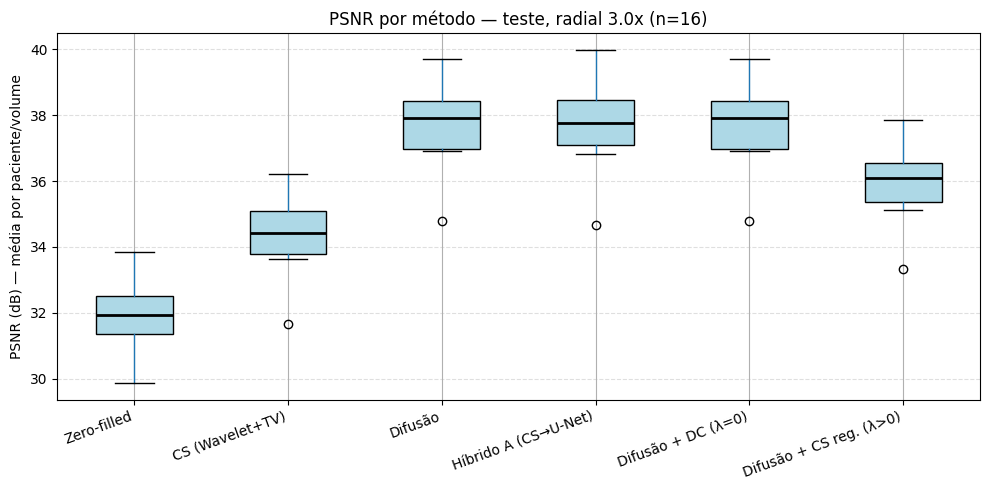

In [12]:
# ============================================================
# 10. Wilcoxon por grupo + Holm + IC bootstrap
# ============================================================
from scipy.stats import wilcoxon

def holm(pvals):
    p = np.asarray(pvals, float); m = len(p)
    order = np.argsort(p); adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

def boot_ci(d, n_boot=5000, seed=SEED):
    r = np.random.RandomState(seed)
    means = [d[r.randint(0, len(d), len(d))].mean() for _ in range(n_boot)]
    return np.percentile(means, [2.5, 97.5])

PAIRS = [
    (M_CS,  M_ZF),    # CS vs zero-filled
    (M_DIF, M_CS),    # difusão vs CS
    (M_A,   M_DIF),   # Híbrido A vs difusão
    (M_B1,  M_DIF),   # DC sobre difusão vs difusão
    (M_B2,  M_DIF),   # CS reg. sobre difusão vs difusão
    (M_B2,  M_B1),    # o prior de CS acrescenta algo além do DC?
]

stat_rows = []
for metric in ["PSNR", "SSIM"]:
    piv = df_grp.pivot(index="grupo", columns="Método", values=metric)
    block = []
    for a, b in PAIRS:
        d = (piv[a] - piv[b]).values
        try:
            p = wilcoxon(piv[a], piv[b], alternative="greater").pvalue
        except ValueError:
            p = float("nan")
        lo, hi = boot_ci(d)
        block.append({"Métrica": metric, "A": a, "B": b, "Δ médio": d.mean(), "IC95% inf": lo, "IC95% sup": hi,
                      "grupos A>B": f"{int((d > 0).sum())}/{len(d)}", "p (A>B)": p})
    ps = np.array([r["p (A>B)"] for r in block])
    ok = ~np.isnan(ps)
    adj = np.full(len(ps), np.nan); adj[ok] = holm(ps[ok])
    for r, pa in zip(block, adj):
        r["p Holm"] = pa
    stat_rows += block

df_stats = pd.DataFrame(stat_rows)
fmt = {"Δ médio": "{:+.4f}".format, "IC95% inf": "{:+.4f}".format, "IC95% sup": "{:+.4f}".format,
       "p (A>B)": "{:.3g}".format, "p Holm": "{:.3g}".format}
print(f"Unidade estatística: {n_g} pacientes/volumes | {len(PAIRS)} comparações por métrica (Holm)\n")
print(df_stats.to_string(index=False, formatters=fmt))
print(f"\nNota: com {n_g} grupos o menor p unilateral possível é {0.5 ** n_g:.3g} (antes de Holm); quando vários p são iguais a esse mínimo, compare os Δ e os ICs, que são mais informativos.")
if n_g < 6:
    print("\nAVISO: com <6 grupos o Wilcoxon unilateral não alcança p<0,05 mesmo com todas as diferenças positivas.")
df_stats.to_csv(os.path.join(WORK_DIR, f"estatistica_{RUN_TAG}.csv"), index=False)

piv = df_grp.pivot(index="grupo", columns="Método", values="PSNR")
plt.figure(figsize=(10, 5))
piv[METHODS].boxplot(patch_artist=True, boxprops=dict(facecolor="lightblue"),
                     medianprops=dict(color="black", linewidth=2))
plt.xticks(rotation=20, ha="right"); plt.ylabel("PSNR (dB) — média por paciente/volume")
plt.title(f"PSNR por método — teste, radial {R_eff:.1f}x (n={n_g})"); plt.grid(axis="y", ls="--", alpha=0.4)
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, f"boxplot_{RUN_TAG}.png"), dpi=150); plt.show()

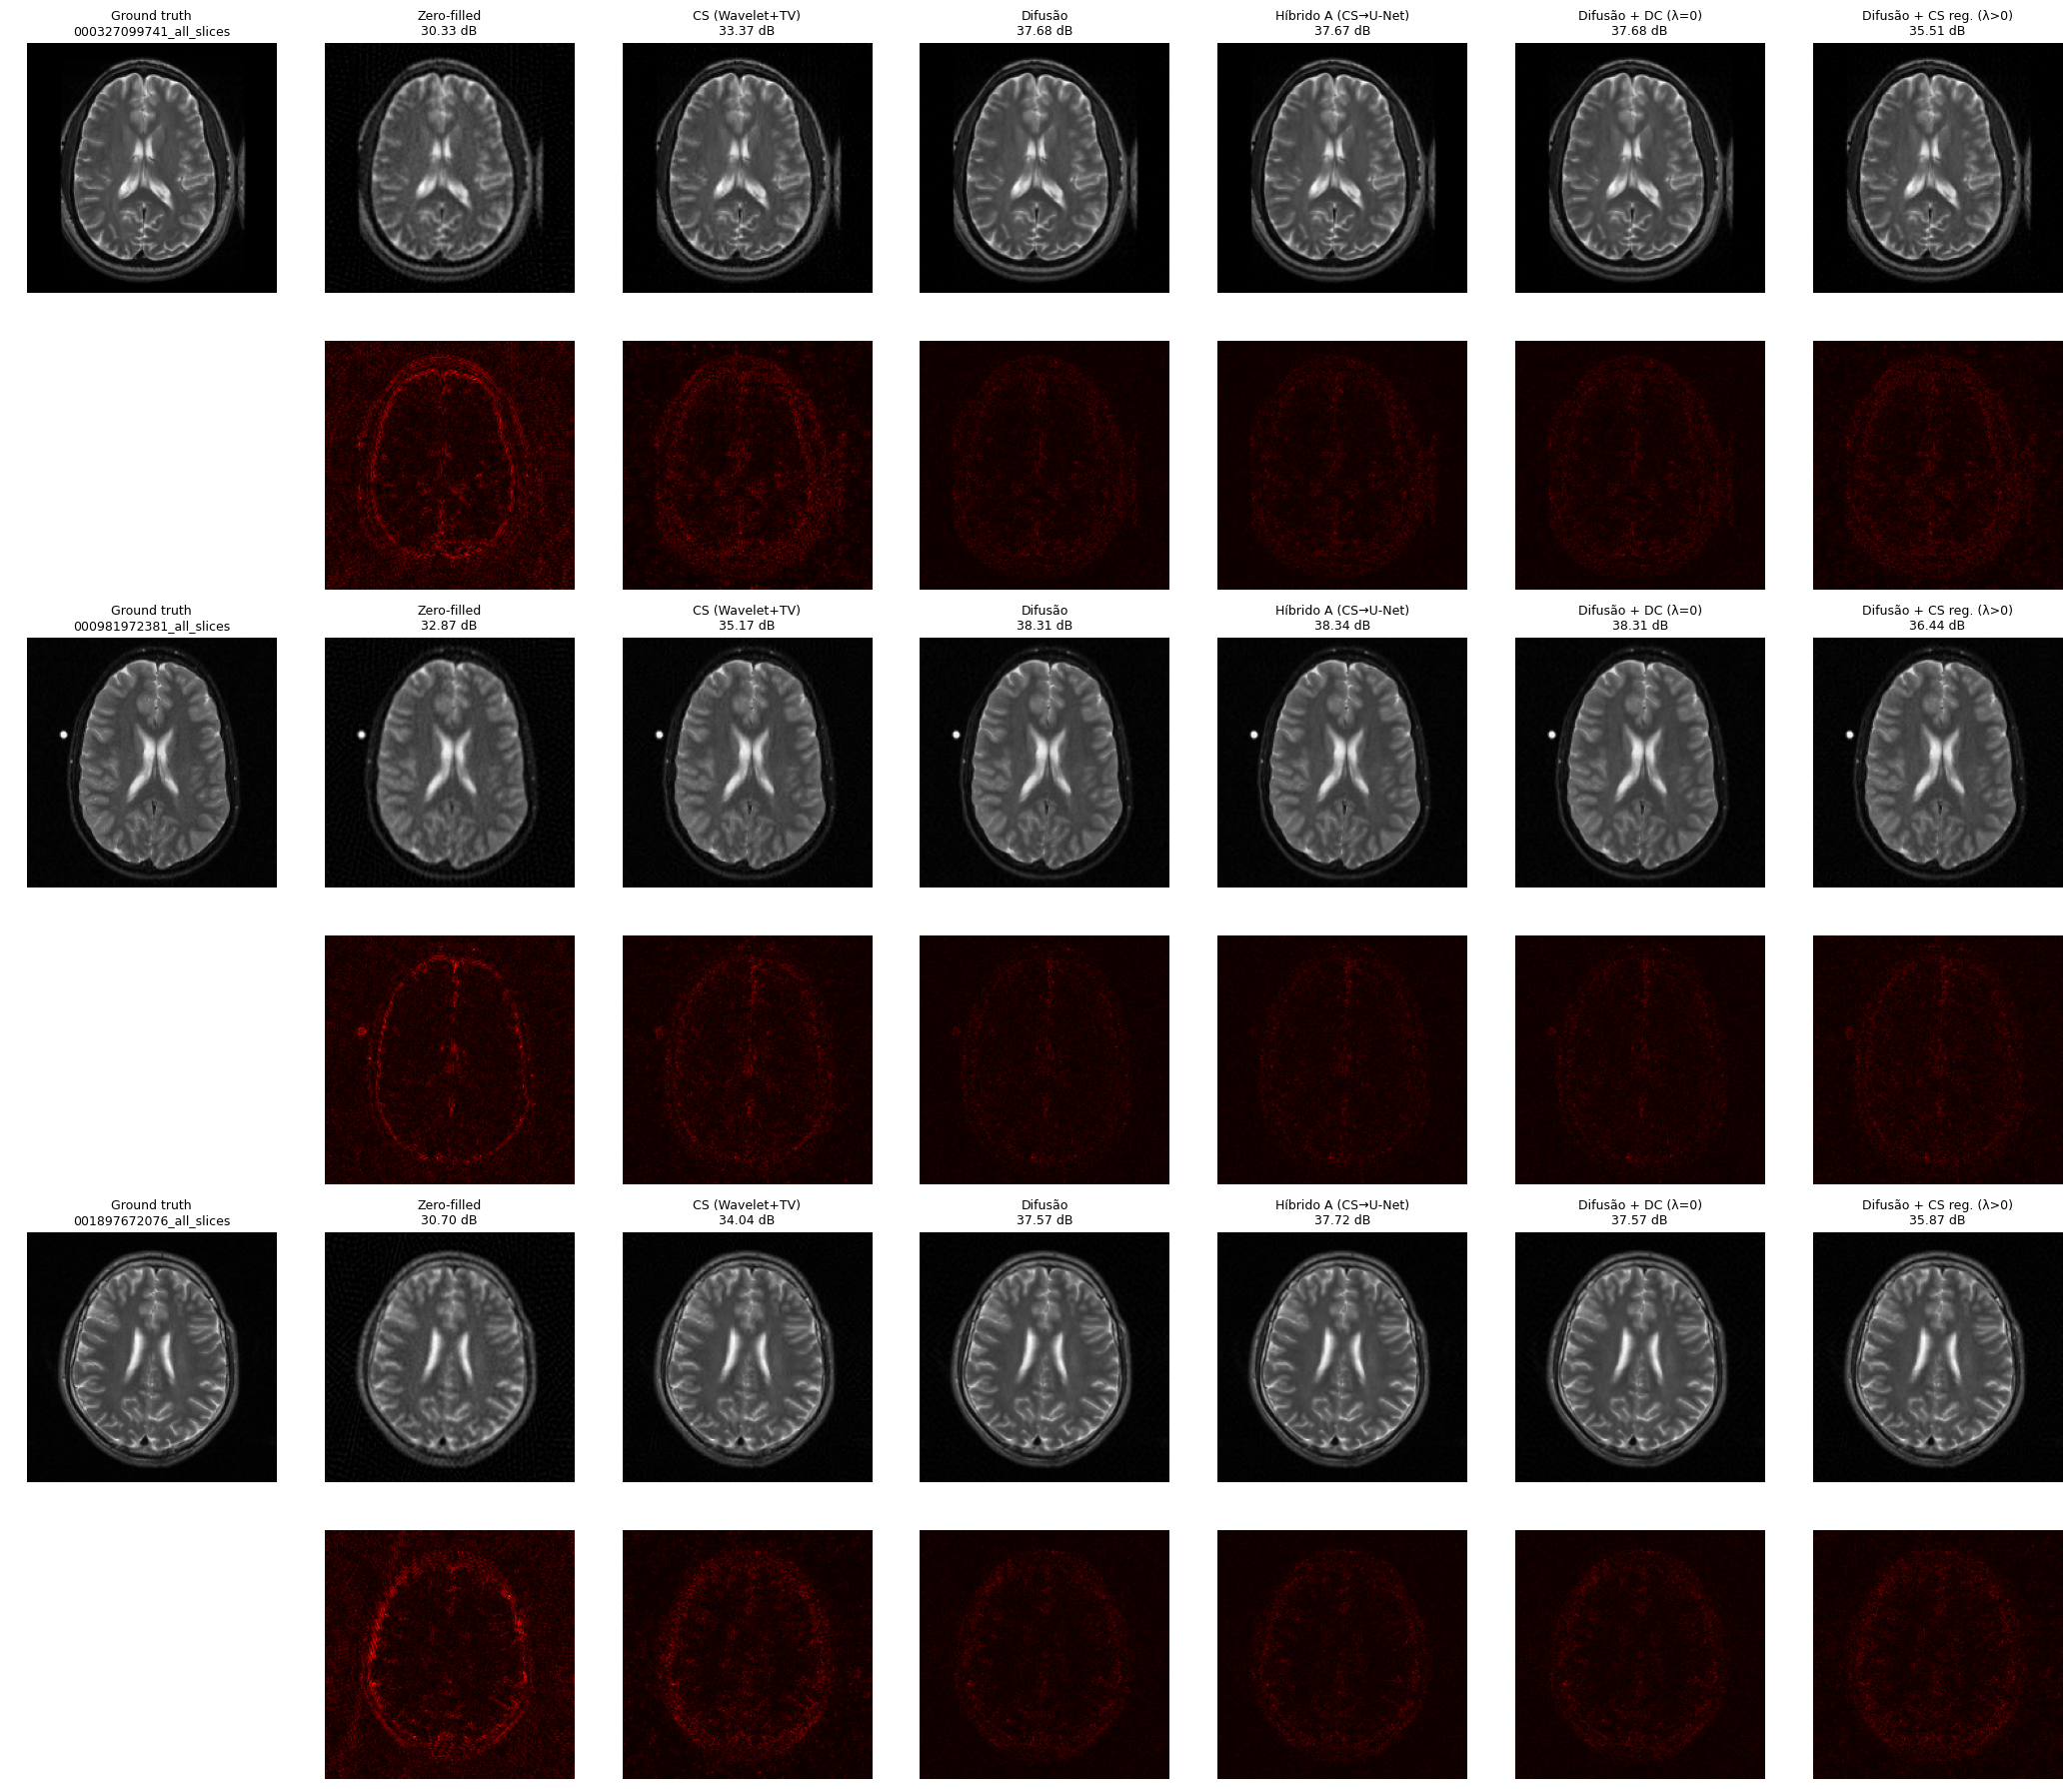

In [13]:
# ============================================================
# 11. Figura: reconstruções e mapas de erro (3 pacientes/volumes diferentes)
# ============================================================
_by_g = {}
for i in idx_test:
    _by_g.setdefault(dataset.group[i], []).append(i)
_gs = sorted(_by_g)
_pick = [_gs[0], _gs[len(_gs) // 2], _gs[-1]]
show = [_by_g[g][len(_by_g[g]) // 2] for g in _pick]

ncol = 1 + len(METHODS)
fig, axes = plt.subplots(2 * len(show), ncol, figsize=(3 * ncol, 6 * len(show)))
titles = ["Ground truth"] + METHODS
for r, i in enumerate(show):
    g, recs = store[i]
    dr = g.max() - g.min()
    axes[2 * r, 0].imshow(g, cmap="gray"); axes[2 * r, 0].set_title(f"Ground truth\n{dataset.group[i]}", fontsize=9)
    for c, (name, rec) in enumerate(zip(METHODS, recs), start=1):
        p = peak_signal_noise_ratio(g, rec, data_range=dr)
        axes[2 * r, c].imshow(rec, cmap="gray", vmin=g.min(), vmax=g.max())
        axes[2 * r, c].set_title(f"{name}\n{p:.2f} dB", fontsize=9)
        axes[2 * r + 1, c].imshow(np.abs(g - rec), cmap="hot", vmin=0, vmax=0.5 * dr)
    for a in axes[2 * r:2 * r + 2].ravel():
        a.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, f"figura_{RUN_TAG}.png"), dpi=200, bbox_inches="tight"); plt.show()

In [14]:
# ============================================================
# 12. Tabela LaTeX
# ============================================================
tab = summary.reset_index().rename(columns={"index": "Método"})
latex = tab.to_latex(index=False, escape=False, column_format="lccccc",
                     caption=(f"Comparação entre zero-filled, CS, difusão e híbridos (trajetória radial, "
                              f"R efetivo = {R_eff:.2f}$\\times$, {len(idx_test)} fatias de {n_g} pacientes/volumes de teste). "
                              f"Média $\\pm$ desvio padrão entre pacientes/volumes."),
                     label=f"tab:{RUN_TAG}")
print(latex)
open(os.path.join(WORK_DIR, f"tabela_latex_{RUN_TAG}.txt"), "w").write(latex)

\begin{table}
\caption{Comparação entre zero-filled, CS, difusão e híbridos (trajetória radial, R efetivo = 3.00$\times$, 80 fatias de 16 pacientes/volumes de teste). Média $\pm$ desvio padrão entre pacientes/volumes.}
\label{tab:v3_radial3x}
\begin{tabular}{lccccc}
\toprule
Método & PSNR (dB) ↑ & SSIM ↑ & NMSE ↓ & Erro DC ↓ & Tempo (s) \\
\midrule
Zero-filled & 31.90 ± 0.96 & 0.8360 ± 0.0209 & 0.02138 ± 0.00619 & 0.0000 ± 0.0000 & 0.00 ± 0.00 \\
CS (Wavelet+TV) & 34.42 ± 1.11 & 0.9212 ± 0.0176 & 0.01229 ± 0.00340 & 0.0169 ± 0.0002 & 0.33 ± 0.01 \\
Difusão & 37.75 ± 1.18 & 0.9604 ± 0.0110 & 0.00559 ± 0.00170 & 0.0000 ± 0.0000 & 0.02 ± 0.00 \\
Híbrido A (CS→U-Net) & 37.77 ± 1.25 & 0.9611 ± 0.0116 & 0.00564 ± 0.00166 & 0.0000 ± 0.0000 & 0.35 ± 0.01 \\
Difusão + DC (λ=0) & 37.75 ± 1.18 & 0.9604 ± 0.0110 & 0.00559 ± 0.00170 & 0.0000 ± 0.0000 & 0.03 ± 0.00 \\
Difusão + CS reg. (λ>0) & 36.00 ± 1.09 & 0.9378 ± 0.0148 & 0.00835 ± 0.00206 & 0.0006 ± 0.0000 & 0.24 ± 0.01 \\
\bottomrule
\end{tabu

1017